# Credit risk with verified counterfactuals

Cleaned, run-in-order version of the exploration notebook. **Kernel → Restart & Run All** reproduces everything.

Sections: 1 Data, 2 Cleaning, 3 Models, 4 Counterfactual engine, 5 Evaluation, 6 Agent, 7 Dashboard export.

**Sanity anchors after a full run** (cutoff 0.10, 1,000 sampled rejections):
- Test AUROC: logistic 0.8584, monotone XGBoost 0.8678
- Both models must agree: about 59% one change is enough, 5% combination, 36% no realistic path
- Sensitivity, baseline row: 74.1% feasible (logistic) and 64.0% (both models)

The DiCE search and the LLM are not fully deterministic, so agent text and combination cases can vary slightly between runs.

In [1]:
import os, re, json, time, random, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.special import logit, expit
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

random.seed(42); np.random.seed(42)

# ---- policy and settings: edit here only ----
CUTOFF = 0.10                                    # approve when predicted default probability is below this
actionable = ["utilization", "monthly_income", "debt_ratio"]
LEVERS = actionable
LIMITS = dict(util_floor=0.10, income_max_mult=1.30, debt_min_mult=0.50)   # what an applicant can realistically change
TOL = {"utilization": 0.01, "monthly_income": 50, "debt_ratio": 0.005}      # smallest change that counts as "changed"
N_SAMPLE = 1000                                  # declined applicants sampled for the evaluation

## 1. Data

In [2]:
df = pd.read_csv("cs-training.csv", index_col=0)
df = df.rename(columns={
    "SeriousDlqin2yrs": "default",
    "RevolvingUtilizationOfUnsecuredLines": "utilization",
    "NumberOfTime30-59DaysPastDueNotWorse": "late_30_59",
    "NumberOfTime60-89DaysPastDueNotWorse": "late_60_89",
    "NumberOfTimes90DaysLate": "late_90",
    "NumberOfOpenCreditLinesAndLoans": "open_credit_lines",
    "NumberRealEstateLoansOrLines": "real_estate_loans",
    "MonthlyIncome": "monthly_income",
    "DebtRatio": "debt_ratio",
    "NumberOfDependents": "dependents",
})

print(df.shape)
print(df["default"].mean())          # expect ~0.067
print(df.isna().mean())              # monthly_income ~20%, dependents ~2.6%
print(df.describe().T)

(150000, 11)
0.06684
default              0.000000
utilization          0.000000
age                  0.000000
late_30_59           0.000000
debt_ratio           0.000000
monthly_income       0.198207
open_credit_lines    0.000000
late_90              0.000000
real_estate_loans    0.000000
late_60_89           0.000000
dependents           0.026160
dtype: float64
                      count         mean           std  min          25%  \
default            150000.0     0.066840      0.249746  0.0     0.000000   
utilization        150000.0     6.048438    249.755371  0.0     0.029867   
age                150000.0    52.295207     14.771866  0.0    41.000000   
late_30_59         150000.0     0.421033      4.192781  0.0     0.000000   
debt_ratio         150000.0   353.005076   2037.818523  0.0     0.175074   
monthly_income     120269.0  6670.221237  14384.674215  0.0  3400.000000   
open_credit_lines  150000.0     8.452760      5.145951  0.0     5.000000   
late_90            150000.

In [3]:
X = df.drop(columns="default")
y = df["default"]

# one impossible age (0)
mask = X["age"] >= 18
X, y = X[mask], y[mask]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# quick check on the 96/98 placeholder codes before deciding how to treat them
late_cols = ["late_30_59", "late_60_89", "late_90"]
code_rows = X_train[late_cols].isin([96, 98]).any(axis=1)
print(code_rows.sum(), y_train[code_rows].mean(), y_train[~code_rows].mean())

215 0.5441860465116279 0.06598544045949375


Debt-ratio check (motivates the cleaning rule below): the ratio is a dollar amount when income is missing.

In [4]:
has_inc = X_train["monthly_income"].notna()
print("share >1 | income present:", (X_train.loc[has_inc, "debt_ratio"] > 1).mean())
print("share >1 | income missing:", (X_train.loc[~has_inc, "debt_ratio"] > 1).mean())
print("p99 | income present:", X_train.loc[has_inc, "debt_ratio"].quantile(0.99))
print("default rate, ratio>5:", y_train[X_train["debt_ratio"] > 5].mean())

share >1 | income present: 0.06000976613229993
share >1 | income missing: 0.9385632474313627
p99 | income present: 655.0
default rate, ratio>5: 0.05461989785150479


## 2. Cleaning
Parameters are fitted on the training set only. Placeholder codes 96/98 become a flag, missing income becomes a flag, and `debt_ratio` is treated as invalid when income is missing or the ratio exceeds 5.

In [5]:
def fit_cleaner(X_tr):
    valid_debt = X_tr["monthly_income"].notna() & (X_tr["debt_ratio"] <= 5)
    return {
        "income_median": X_tr["monthly_income"].median(),
        "income_cap": X_tr["monthly_income"].quantile(0.995),
        "debt_median": X_tr.loc[valid_debt, "debt_ratio"].median(),
        "dep_median": X_tr["dependents"].median(),
        "late_median": X_tr[late_cols].replace([96, 98], np.nan).median(),
    }

def apply_cleaner(X_in, p):
    X_out = X_in.copy()

    X_out["late_code_flag"] = X_out[late_cols].isin([96, 98]).any(axis=1).astype(int)
    for c in late_cols:
        X_out[c] = X_out[c].replace([96, 98], np.nan).fillna(p["late_median"][c])

    X_out["income_missing"] = X_out["monthly_income"].isna().astype(int)
    X_out["monthly_income"] = X_out["monthly_income"].fillna(p["income_median"]).clip(upper=p["income_cap"])

    bad_debt = X_out["income_missing"].eq(1) | (X_out["debt_ratio"] > 5)
    X_out["debt_ratio"] = X_out["debt_ratio"].mask(bad_debt, p["debt_median"]).clip(0, 5)

    X_out["utilization"] = X_out["utilization"].clip(0, 2.0)
    X_out["dependents"] = X_out["dependents"].fillna(p["dep_median"])
    return X_out

params = fit_cleaner(X_train)
X_train_c = apply_cleaner(X_train, params)
X_test_c = apply_cleaner(X_test, params)

cols = list(X_train_c.columns)
print(X_train_c["debt_ratio"].describe())

count    119999.000000
mean          0.345719
std           0.333165
min           0.000000
25%           0.183956
50%           0.290933
75%           0.410510
max           5.000000
Name: debt_ratio, dtype: float64


## 3. Models
Logistic regression is the transparent model. XGBoost is trained twice: unconstrained (comparison only) and with monotone constraints, which the counterfactual search needs.

In [6]:
def evaluate(name, model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    p = model.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(yte, p)
    fpr, tpr, _ = roc_curve(yte, p)
    print(f"{name:10s} AUROC={auc:.4f}  Gini={2*auc-1:.4f}  "
          f"KS={np.max(tpr-fpr):.4f}  Brier={brier_score_loss(yte, p):.4f}")
    return model, p

lr, p_lr = evaluate("LogReg", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                    X_train_c, y_train, X_test_c, y_test)

xgb, p_xgb = evaluate("XGBoost", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.8, eval_metric="auc", random_state=42),
                      X_train_c, y_train, X_test_c, y_test)

# monotone constraints: risk may only rise with utilization, debt ratio and late counts, and only fall with income
mono = {c: 0 for c in cols}
mono.update(utilization=1, debt_ratio=1, monthly_income=-1, late_30_59=1, late_60_89=1, late_90=1)
xgb_m, p_xgb_m = evaluate("XGB-mono", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, eval_metric="auc", random_state=42,
                          monotone_constraints=tuple(mono[c] for c in cols)),
                          X_train_c, y_train, X_test_c, y_test)

scaler, clf = lr[0], lr[-1]

LogReg     AUROC=0.8584  Gini=0.7168  KS=0.5619  Brier=0.0508
XGBoost    AUROC=0.8691  Gini=0.7383  KS=0.5836  Brier=0.0488
XGB-mono   AUROC=0.8678  Gini=0.7355  KS=0.5785  Brier=0.0492


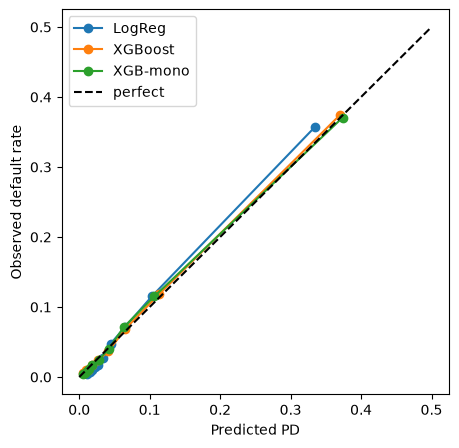

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
for name, p in [("LogReg", p_lr), ("XGBoost", p_xgb), ("XGB-mono", p_xgb_m)]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 0.5], [0, 0.5], "k--", label="perfect")
ax.set_xlabel("Predicted PD"); ax.set_ylabel("Observed default rate"); ax.legend()
plt.show()

In [8]:
coefs = pd.Series(lr[-1].coef_[0], index=X_train_c.columns).sort_values()
print(coefs)

res = pd.DataFrame({"pd": p_lr, "y": y_test.values})
thr_rows = []
for cut in [0.04, 0.06, 0.08, 0.10, 0.15, 0.20]:
    appr = res[res.pd < cut]
    thr_rows.append({
        "cutoff": cut,
        "approval_rate": len(appr) / len(res),
        "bad_rate_approved": appr.y.mean(),
        "defaults_caught": 1 - appr.y.sum() / res.y.sum(),
    })
print(pd.DataFrame(thr_rows).round(3))

age                 -0.259707
monthly_income      -0.123600
income_missing      -0.009918
dependents           0.053813
debt_ratio           0.068891
real_estate_loans    0.083249
late_code_flag       0.100493
open_credit_lines    0.115679
late_60_89           0.208378
late_30_59           0.302277
late_90              0.329181
utilization          0.644849
dtype: float64
   cutoff  approval_rate  bad_rate_approved  defaults_caught
0    0.04          0.620              0.013            0.876
1    0.06          0.734              0.019            0.788
2    0.08          0.800              0.024            0.707
3    0.10          0.846              0.028            0.639
4    0.15          0.916              0.037            0.496
5    0.20          0.939              0.043            0.401


## 4. Counterfactual engine
Everything an applicant can change goes through `apply_levers`. A counterfactual counts only if the **higher** of the two models' risks is under the cutoff (`pd_cons`).

In [9]:
def lever_bounds(row):
    return {
        "utilization":    [min(LIMITS["util_floor"], row.utilization), float(row.utilization)],
        "monthly_income": [float(row.monthly_income),
                           float(min(row.monthly_income * LIMITS["income_max_mult"], params["income_cap"]))],
        "debt_ratio":     [float(row.debt_ratio * LIMITS["debt_min_mult"]), float(row.debt_ratio)],
    }

def apply_levers(row, u, inc, dr):
    """Build the modified applicant. Debt ratio gets credit for higher income
    (same monthly debt over a bigger income), which only helps, so validity holds."""
    r = row.copy()
    r["utilization"], r["monthly_income"] = u, inc
    r["debt_ratio"] = min(dr, row.debt_ratio * row.monthly_income / max(inc, 1))
    return r

def pd_of(r):                                   # logistic model
    return lr.predict_proba(pd.DataFrame([r])[cols].astype(float))[0, 1]

def pd_xgb(r):                                  # monotone gradient-boosted model
    return xgb_m.predict_proba(pd.DataFrame([r])[cols].astype(float))[0, 1]

def pd_cons(r):                                 # consensus: the more cautious of the two
    return max(pd_of(r), pd_xgb(r))

def realistic_floor(row, score=pd_of):
    """Lowest risk reachable within the limits (exact because both models are monotone in each lever)."""
    b = lever_bounds(row)
    inc = row.monthly_income if row.income_missing == 1 else b["monthly_income"][1]
    return score(apply_levers(row, b["utilization"][0], inc, b["debt_ratio"][0]))

def round_lever(lever, v):
    return {"utilization": np.floor(v * 20) / 20,          # 0.05 steps, toward lower
            "monthly_income": np.ceil(v / 100) * 100,      # nearest 100, toward higher
            "debt_ratio": np.floor(v * 100) / 100}[lever]  # 0.01 steps, toward lower

def single_lever_options(row, cutoff=CUTOFF, margin=0.005, score=pd_of, iters=20):
    """Smallest change in ONE lever that brings risk under the cutoff (bisection)."""
    b, opts = lever_bounds(row), []
    for lever, extreme in [("utilization", b["utilization"][0]),
                           ("monthly_income", b["monthly_income"][1]),
                           ("debt_ratio", b["debt_ratio"][0])]:
        cur = float(row[lever])
        if (lever == "monthly_income" and row.income_missing == 1) or abs(extreme - cur) < 1e-9:
            continue
        def at(v):
            kw = dict(utilization=row.utilization, income=row.monthly_income, dr=row.debt_ratio)
            kw[{"utilization": "utilization", "monthly_income": "income", "debt_ratio": "dr"}[lever]] = v
            return apply_levers(row, kw["utilization"], kw["income"], kw["dr"])
        if score(at(extreme)) >= cutoff - margin:
            continue
        lo, hi = 0.0, 1.0
        for _ in range(iters):
            mid = (lo + hi) / 2
            lo, hi = (lo, mid) if score(at(cur + mid * (extreme - cur))) < cutoff - margin else (mid, hi)
        v = round_lever(lever, cur + hi * (extreme - cur))
        r = at(v)
        if score(r) < cutoff:
            opts.append(dict(lever=lever, from_=round(cur, 3), to=round(float(v), 3),
                             new_PD=round(float(score(r)), 3)))
    return opts

def shrink(row, cf, cutoff, score, margin=0.005):
    """Smallest move along the segment original -> cf that stays under cutoff - margin."""
    o = (row.utilization, row.monthly_income, row.debt_ratio)
    c = (cf.utilization, cf.monthly_income, cf.debt_ratio)
    point = lambda t: apply_levers(row, *[a + t * (b - a) for a, b in zip(o, c)])
    if score(point(1.0)) >= cutoff - margin:
        return point(1.0)
    lo, hi = 0.0, 1.0
    for _ in range(20):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if score(point(mid)) < cutoff - margin else (mid, hi)
    return point(hi)

def tidy(r, row):
    """Round in the direction that helps the applicant."""
    r = r.copy()
    r["utilization"]    = np.floor(r.utilization * 20) / 20           # 0.05 steps
    r["monthly_income"] = np.ceil(r.monthly_income / 100) * 100        # nearest 100 up
    r["debt_ratio"]     = np.floor(r.debt_ratio * 100) / 100
    r["debt_ratio"]     = min(r.debt_ratio, row.debt_ratio * row.monthly_income / r.monthly_income)
    return r

DiCE handles combinations of levers. Its model wrapper shifts the probability so that DiCE's 0.5 boundary is exactly the consensus risk equal to the cutoff.

In [10]:
import dice_ml

class ConsensusModel:
    """DiCE's 0.5 boundary == (higher PD of the models) = cutoff."""
    def __init__(self, models, cutoff):
        self.models, self.shift = models, logit(cutoff)
    def predict_proba(self, X):
        p = np.max([m.predict_proba(X)[:, 1] for m in self.models], axis=0)
        s = expit(logit(np.clip(p, 1e-9, 1 - 1e-9)) - self.shift)
        return np.column_stack([1 - s, s])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

train_df = X_train_c.copy()
train_df["default"] = y_train.values
d = dice_ml.Data(dataframe=train_df, continuous_features=list(X_train_c.columns), outcome_name="default")
exp = dice_ml.Dice(d, dice_ml.Model(model=ConsensusModel([lr, xgb_m], CUTOFF), backend="sklearn"),
                   method="genetic")

def actionable_cfs(row, cutoff=CUTOFF, n_cfs=10, keep=3, score=pd_cons):
    q = pd.DataFrame([row])[cols]
    cur, floor = pd_of(row), realistic_floor(row, score=score)
    if floor >= cutoff:
        return dict(status="infeasible", pd=cur, floor=floor, cfs=None)

    vary = [f for f in actionable if not (f == "monthly_income" and row.income_missing == 1)]
    cf = exp.generate_counterfactuals(
        q, total_CFs=n_cfs, desired_class=0, features_to_vary=vary, posthoc_sparsity_param=None,
        permitted_range={k: v for k, v in lever_bounds(row).items() if k in vary})
    raw = cf.cf_examples_list[0].final_cfs_df
    if raw is None:
        return dict(status="search_failed", pd=cur, floor=floor, cfs=None)

    out = []
    for _, c in raw.iterrows():
        r = tidy(shrink(row, c, cutoff, score), row)
        if score(r) < cutoff:
            out.append(dict(r[actionable], new_PD=score(r)))
    df = pd.DataFrame(out).drop_duplicates(subset=actionable)
    if df.empty:
        return dict(status="search_failed", pd=cur, floor=floor, cfs=None)
    df["effort"] = ((row.utilization - df.utilization) / max(row.utilization, 1e-6)
                    + (df.monthly_income - row.monthly_income) / max(row.monthly_income, 1)
                    + (row.debt_ratio - df.debt_ratio) / max(row.debt_ratio, 1e-6))
    return dict(status="ok", pd=cur, floor=floor, cfs=df.sort_values("effort").head(keep), current=row[actionable])

## 5. Evaluation
First the two properties the engine relies on, then the results on a random sample of declined applicants.

In [11]:
def mono_violations(model, n=200):
    """Share of applicants whose predicted PD is NOT monotone as utilization is swept 0 -> 1.5."""
    grid, bad = np.linspace(0, 1.5, 16), 0
    for i in sample_idx[:n]:
        row = X_test_c.loc[i]
        sweep = pd.DataFrame([apply_levers(row, u, row.monthly_income, row.debt_ratio)[cols]
                              for u in grid]).astype(float)
        bad += (np.diff(model.predict_proba(sweep)[:, 1]) < -1e-9).any()
    return bad / n

rej_idx = X_test_c.index[p_lr >= CUTOFF]
print(f"rejected: {len(rej_idx)} of {len(X_test_c)} ({len(rej_idx)/len(X_test_c):.1%})")
sample_idx = np.random.default_rng(42).choice(rej_idx, size=min(N_SAMPLE, len(rej_idx)), replace=False)

print("non-monotone in utilization, unconstrained XGB:", mono_violations(xgb))
print("non-monotone in utilization, monotone XGB:     ", mono_violations(xgb_m))

rejected: 4615 of 30000 (15.4%)
non-monotone in utilization, unconstrained XGB: 0.995
non-monotone in utilization, monotone XGB:      0.0


In [12]:
def batch_detail(score, idxs=sample_idx):
    recs = []
    for idx in tqdm(idxs):
        row = X_test_c.loc[idx]
        floor = realistic_floor(row, score=score)
        opts = single_lever_options(row, score=score) if floor < CUTOFF else []
        rec = dict(idx=idx, pd=pd_of(row), floor=floor, feasible=floor < CUTOFF, n_single=len(opts),
                   **{f"chg_{l}": np.nan for l in LEVERS})
        for o in opts:
            rec[f"chg_{o['lever']}"] = abs(o["to"] - o["from_"]) / max(abs(o["from_"]), 1e-6)
        recs.append(rec)
    d_ = pd.DataFrame(recs)
    d_["category"] = np.select([~d_.feasible, d_.n_single > 0],
                               ["infeasible", "single-lever fix exists"], "combination needed")
    return d_

def show_batch(d_, title):
    print(f"\n== {title} ==")
    print(d_.category.value_counts(normalize=True).round(3).to_string())
    for l in LEVERS:
        c = d_[f"chg_{l}"].dropna()
        print(f"  {l:15s} sufficient alone: {len(c)/len(d_):5.1%}" + (f"   median relative change {c.median():.1%}" if len(c) else ""))
    print("  mean PD at decline by outcome:", d_.groupby("category")["pd"].mean().round(3).to_dict())

R_lr   = batch_detail(pd_of);   show_batch(R_lr,   "logistic model alone")
R_cons = batch_detail(pd_cons); show_batch(R_cons, "both models must agree (monotone XGB)")

cmp = pd.concat([R_lr.category.value_counts(normalize=True).rename("logistic only"),
                 R_cons.category.value_counts(normalize=True).rename("consensus, monotone XGB")], axis=1)
print(); print(cmp.round(3))

100%|██████████| 1000/1000 [01:28<00:00, 11.25it/s]



== logistic model alone ==
category
single-lever fix exists    0.700
infeasible                 0.259
combination needed         0.041
  utilization     sufficient alone: 70.0%   median relative change 30.0%
  monthly_income  sufficient alone:  1.1%   median relative change 27.1%
  debt_ratio      sufficient alone:  1.1%   median relative change 40.8%
  mean PD at decline by outcome: {'combination needed': 0.255, 'infeasible': 0.536, 'single-lever fix exists': 0.162}


100%|██████████| 1000/1000 [03:14<00:00,  5.14it/s]


== both models must agree (monotone XGB) ==
category
single-lever fix exists    0.592
infeasible                 0.360
combination needed         0.048
  utilization     sufficient alone: 59.2%   median relative change 36.9%
  monthly_income  sufficient alone:  0.9%   median relative change 28.0%
  debt_ratio      sufficient alone:  0.7%   median relative change 40.8%
  mean PD at decline by outcome: {'combination needed': 0.202, 'infeasible': 0.457, 'single-lever fix exists': 0.15}

                         logistic only  consensus, monotone XGB
category                                                       
single-lever fix exists          0.700                    0.592
infeasible                       0.259                    0.360
combination needed               0.041                    0.048


### Sensitivity to the limits on what an applicant can change

In [13]:
configs = {
    "tighter":      dict(util_floor=0.20, income_max_mult=1.15, debt_min_mult=0.75),
    "baseline":     dict(util_floor=0.10, income_max_mult=1.30, debt_min_mult=0.50),
    "income +50%":  dict(util_floor=0.10, income_max_mult=1.50, debt_min_mult=0.50),
    "util to 0":    dict(util_floor=0.00, income_max_mult=1.30, debt_min_mult=0.50),
    "all relaxed":  dict(util_floor=0.00, income_max_mult=2.00, debt_min_mult=0.00),
}
saved, sens_rows = LIMITS.copy(), []
try:
    for name, cfg in configs.items():
        LIMITS.update(cfg)
        fl_lr  = np.array([realistic_floor(X_test_c.loc[i], score=pd_of)   for i in tqdm(sample_idx, desc=name)])
        fl_con = np.array([realistic_floor(X_test_c.loc[i], score=pd_cons) for i in sample_idx])
        sens_rows.append(dict(config=name, feasible_logistic=(fl_lr < CUTOFF).mean(),
                              feasible_consensus=(fl_con < CUTOFF).mean(),
                              near_miss_consensus=((fl_con >= CUTOFF) & (fl_con < CUTOFF + 0.03)).mean()))
finally:
    LIMITS.update(saved)                         # always restore, even if interrupted
print(pd.DataFrame(sens_rows).round(3))

all relaxed: 100%|██████████| 1000/1000 [00:04<00:00, 238.61it/s]


        config  feasible_logistic  feasible_consensus  near_miss_consensus
0      tighter              0.681               0.573                0.087
1     baseline              0.741               0.640                0.069
2  income +50%              0.747               0.645                0.069
3    util to 0              0.766               0.660                0.064
4  all relaxed              0.781               0.720                0.066


### Why do some applicants have no realistic path?

In [14]:
fl = pd.Series({i: realistic_floor(X_test_c.loc[i], score=pd_cons) for i in sample_idx})
inf_idx = fl[fl >= CUTOFF].index

Z = (X_test_c.loc[inf_idx, cols].values - scaler.mean_) / scaler.scale_
contrib_df = pd.DataFrame(Z * clf.coef_[0], index=inf_idx, columns=cols)

fixed = ["late_code_flag", "late_30_59", "late_60_89", "late_90", "age",
         "open_credit_lines", "real_estate_loans", "dependents"]
print("infeasible applicants:", len(inf_idx))
print("share with the 96/98 flag:", X_test_c.loc[inf_idx, "late_code_flag"].mean().round(3))
print("\nLargest fixed driver among infeasible applicants:")
print(contrib_df[fixed].idxmax(axis=1).value_counts(normalize=True).round(3))

infeasible applicants: 360
share with the 96/98 flag: 0.047

Largest fixed driver among infeasible applicants:
late_90              0.447
late_30_59           0.347
late_60_89           0.150
late_code_flag       0.047
real_estate_loans    0.006
age                  0.003
Name: proportion, dtype: float64


### Ablations (optional, about 5 minutes)
What the earlier, weaker designs would have said. These are comparisons only; the results above are the ones to quote.

In [15]:
# (a) consensus with the UNCONSTRAINED XGBoost: spurious risk bumps make some applicants look unfixable
def pd_cons_unc(r):
    return max(pd_of(r), xgb.predict_proba(pd.DataFrame([r])[cols].astype(float))[0, 1])

R_unc = batch_detail(pd_cons_unc)
cmp["consensus, unconstrained XGB (ablation)"] = R_unc.category.value_counts(normalize=True)
print(cmp.round(3))

100%|██████████| 1000/1000 [02:37<00:00,  6.33it/s]

                         logistic only  consensus, monotone XGB  \
category                                                          
single-lever fix exists          0.700                    0.592   
infeasible                       0.259                    0.360   
combination needed               0.041                    0.048   

                         consensus, unconstrained XGB (ablation)  
category                                                          
single-lever fix exists                                    0.510  
infeasible                                                 0.433  
combination needed                                         0.057  


In [16]:
# (b) how often do logistic-only counterfactuals hold up under the unconstrained XGBoost?
def rebuild(row, lever, to):
    u, inc, dr = row.utilization, row.monthly_income, row.debt_ratio
    if lever == "utilization":     u = to
    elif lever == "monthly_income": inc = to
    elif lever == "debt_ratio":     dr = to
    return apply_levers(row, u, inc, dr)

fix_idx = R_lr.loc[R_lr.category == "single-lever fix exists", "idx"]
orig, mod, meta = [], [], []
for idx in tqdm(fix_idx):
    row = X_test_c.loc[idx]
    for o in single_lever_options(row):
        orig.append(row[cols]); mod.append(rebuild(row, o["lever"], o["to"])[cols])
        meta.append((idx, o["lever"], o["new_PD"]))

orig, mod = pd.DataFrame(orig).astype(float), pd.DataFrame(mod).astype(float)
C = pd.DataFrame(meta, columns=["idx", "lever", "lr_new_pd"])
C["xgb_old"] = xgb.predict_proba(orig)[:, 1]
C["xgb_new"] = xgb.predict_proba(mod)[:, 1]

print("options checked:", len(C))
print("XGBoost would also have declined the applicant:", f"{(C.xgb_old >= CUTOFF).mean():.1%}")
print("XGBoost says risk falls at all:               ", f"{(C.xgb_new < C.xgb_old).mean():.1%}")
print("XGBoost puts the new PD under the cutoff:     ", f"{(C.xgb_new < CUTOFF).mean():.1%}")
print("XGBoost new PD under cutoff + 0.02 tolerance: ", f"{(C.xgb_new < CUTOFF + 0.02).mean():.1%}")
print(C.groupby("lever")[["lr_new_pd", "xgb_old", "xgb_new"]].mean().round(3))

100%|██████████| 700/700 [00:57<00:00, 12.19it/s]


options checked: 722
XGBoost would also have declined the applicant: 78.5%
XGBoost says risk falls at all:                93.5%
XGBoost puts the new PD under the cutoff:      41.7%
XGBoost new PD under cutoff + 0.02 tolerance:  59.6%
                lr_new_pd  xgb_old  xgb_new
lever                                      
debt_ratio          0.095    0.113    0.094
monthly_income      0.095    0.098    0.090
utilization         0.092    0.192    0.132


In [17]:
C["lr_old"] = lr.predict_proba(orig)[:, 1]

# 1) Restrict to cases where BOTH models decline (removes the baseline disagreement)
both = C[C.xgb_old >= CUTOFF]
print(f"both decline: {len(both)} options; XGB clears the cutoff for {(both.xgb_new < CUTOFF).mean():.1%}")

# 2) How big an effect does each model see for the same changes?
print("median PD drop      LR:", round((C.lr_old - C.lr_new_pd).median(), 3),
      " XGB:", round((C.xgb_old - C.xgb_new).median(), 3))
print("median relative drop LR:", round((1 - C.lr_new_pd / C.lr_old).median(), 3),
      " XGB:", round((1 - C.xgb_new / C.xgb_old).median(), 3))

# 3) Where does the logistic model go wrong? Observed vs predicted by utilization bin (test set)
bins = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 1.1, 2.0]
t = X_test_c[["utilization"]].copy()
t["bin"] = pd.cut(t.utilization, bins, include_lowest=True)
t["observed"] = y_test.values
t["LR"] = lr.predict_proba(X_test_c)[:, 1]
t["XGB"] = xgb.predict_proba(X_test_c)[:, 1]
out = t.groupby("bin", observed=True)[["observed", "LR", "XGB"]].mean().round(3)
out["n"] = t.groupby("bin", observed=True).size()
print(out)

both decline: 567 options; XGB clears the cutoff for 26.5%
median PD drop      LR: 0.043  XGB: 0.034
median relative drop LR: 0.321  XGB: 0.224
               observed     LR    XGB      n
bin                                         
(-0.001, 0.1]     0.017  0.021  0.019  12722
(0.1, 0.3]        0.033  0.034  0.031   5863
(0.3, 0.5]        0.064  0.056  0.057   3117
(0.5, 0.7]        0.090  0.086  0.094   2292
(0.7, 0.9]        0.140  0.140  0.146   1930
(0.9, 1.0]        0.197  0.193  0.196   3423
(1.0, 1.1]        0.384  0.311  0.365    375
(1.1, 2.0]        0.371  0.453  0.380    278


## 6. Agent
A LangGraph pipeline: score, then reasons, counterfactuals and an LLM explanation, then a report. Numbers come from the functions above; the LLM only rephrases, and a check flags any number in the text that was not in the facts. Applicants whose file contains the 96/98 codes go to manual review.

In [18]:
from dotenv import load_dotenv
from typing import TypedDict
from langgraph.graph import StateGraph, END
from groq import Groq

load_dotenv()
client = Groq(api_key=os.environ["GROQ_API_KEY"])

In [19]:
LABELS = {"utilization": "High use of revolving credit limits",
          "late_30_59": "Recent 30-59 day late payments", "late_60_89": "Recent 60-89 day late payments",
          "late_90": "90+ day late payments", "open_credit_lines": "Number of open credit lines",
          "real_estate_loans": "Number of real estate loans", "debt_ratio": "High debt relative to income",
          "monthly_income": "Income level", "dependents": "Number of dependents"}
LABELS["late_code_flag"] = "Special delinquency codes in the credit file's late-payment history"
EXCLUDE = {"age", "income_missing"}   # age is never shown as a reason

def reason_codes(row, k=3):
    x = pd.DataFrame([row])[cols].astype(float).values[0]
    contrib = pd.Series(clf.coef_[0] * (x - scaler.mean_) / scaler.scale_, index=cols)
    top = contrib.drop(labels=list(EXCLUDE)).sort_values(ascending=False)
    return [dict(factor=LABELS[f], feature=f, actionable=f in actionable)
            for f, v in top.items() if v > 0][:k]

In [20]:
# --- 2) number check (value-based, ignores "Option 1" style labels) ---
def nums(text):
    text = re.sub(r"(?i)\boption\s+\d+", "", text)
    text = re.sub(r"(?m)^\s*\d+[.)]\s", "", text)
    return [float(n) for n in re.findall(r"\d+(?:\.\d+)?", text.replace(",", ""))]

def check_numbers(text, facts):
    allowed = set()
    for n in nums(json.dumps(facts)):
        allowed |= {round(n, 3), round(n * 100, 1), round(n * 100, 0)}
    return [n for n in nums(text) if round(n, 3) not in allowed and round(n, 1) not in allowed]

# --- 3) state (every key a node returns must be listed here) ---
class AgentState(TypedDict, total=False):
    idx: int
    row: dict
    pd_score: float
    decision: str
    reasons: list
    fixed_factors: list
    status: str
    floor: float
    option_texts: list
    explanation: str
    number_check: list
    report: str

# --- 4) option text is built in code; the LLM only rephrases ---
PHRASE = {
    "utilization":    lambda a, b: f"lower revolving credit utilization from {a*100:.0f}% to {b*100:.0f}%",
    "monthly_income": lambda a, b: f"raise monthly income from {a:,.0f} to {b:,.0f}",
    "debt_ratio":     lambda a, b: f"lower the debt-to-income ratio from {a:.2f} to {b:.2f}",
}
def option_text(changes, new_pd):
    acts = " and ".join(PHRASE[l](a, b) for l, (a, b) in changes.items())
    return f"{acts[0].upper() + acts[1:]}: estimated default risk {new_pd*100:.1f}% (below the {CUTOFF*100:.0f}% cutoff)"

# --- 5) nodes ---
def score_applicant(s):
    row = X_test_c.loc[s["idx"]]
    p = float(pd_of(row))
    return {"row": row.to_dict(), "pd_score": p, "decision": "approved" if p < CUTOFF else "declined"}

def route(s):
    if s["decision"] == "approved":
        return "compile"
    return "review" if s["row"]["late_code_flag"] == 1 else "reasons"

def get_reasons(s):
    rs = reason_codes(pd.Series(s["row"]))
    return {"reasons": rs, "fixed_factors": [r["factor"] for r in rs if not r["actionable"]]}

def get_counterfactuals(s):
    row = pd.Series(s["row"])
    floor = realistic_floor(row, score=pd_cons)
    texts = []
    if floor < CUTOFF:
        texts = [option_text({o["lever"]: (o["from_"], o["to"])}, o["new_PD"])
                 for o in single_lever_options(row, score=pd_cons)]
        if not texts:                                    # DiCE only when no single change is enough
            res = actionable_cfs(row)
            if res["cfs"] is not None and len(res["cfs"]):
                c = res["cfs"].iloc[0]
                ch = {f: (float(row[f]), float(c[f])) for f in actionable if abs(c[f] - row[f]) > TOL[f]}
                if ch:
                    texts.append(option_text(ch, float(c.new_PD)))
    status = "ok" if texts else ("infeasible" if floor >= CUTOFF else "none_found")
    return {"option_texts": texts, "status": status, "floor": round(float(floor), 3)}

SYSTEM = """You write adverse-action style explanations for declined credit applicants.
Use ONLY the facts provided; never invent, recompute or convert any number. Say 'the model estimates';
never promise approval. Do not mention age or any protected characteristic. Plain, respectful tone, under 170 words.
Structure: (1) the main reasons, using the exact factor labels. If fixed_factors is non-empty, say those factors
cannot be changed quickly; say nothing about payment history or loans unless they appear in the reasons.
(2) If status is 'ok', present each item in option_texts as a separate alternative labelled A, B (letters, never
digits), rephrased naturally, stating that the resulting risk is below the cutoff. Say once that post-change risk is
the more cautious of two models. (3) If status is 'infeasible', say plainly that no realistic change in
utilization, income or debt ratio is enough right now, give best_case_risk_pct, and offer no alternatives."""

def explain(s):
    facts = dict(estimated_default_risk_pct=round(s["pd_score"] * 100, 1), lender_cutoff_pct=CUTOFF * 100,
                 reasons=[r["factor"] for r in s["reasons"]], fixed_factors=s["fixed_factors"],
                 status=s["status"], option_texts=s["option_texts"])
    if s["status"] == "infeasible":
        facts["best_case_risk_pct"] = round(s["floor"] * 100, 1)
    r = client.chat.completions.create(
        model="openai/gpt-oss-120b", temperature=0.2, max_tokens=1500, reasoning_effort="low",
        messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": json.dumps(facts)}])
    text = r.choices[0].message.content
    return {"explanation": text, "number_check": check_numbers(text, facts)}

def compile_report(s):
    head = f"Applicant {s['idx']}: {s['decision'].upper()} (estimated default risk {s['pd_score']:.1%}, cutoff {CUTOFF:.0%})"
    if s["decision"] == "approved":
        return {"report": head}
    flag = f"\n\n[unverified numbers in text: {s['number_check']}]" if s["number_check"] else ""
    return {"report": f"{head}\n\n{s['explanation']}{flag}"}

def manual_review(s):
    return {"report": (f"Applicant {s['idx']}: DECLINED by model (estimated default risk {s['pd_score']:.1%}). "
                       "REFERRED FOR MANUAL REVIEW: the credit file contains special delinquency codes (96/98) "
                       "that may be data placeholders; automated reasons and recommendations withheld.")}

In [21]:
# graph: rebuild this cell whenever any node function above changes
g = StateGraph(AgentState)
for name, fn in [("score", score_applicant), ("reasons", get_reasons), ("counterfactuals", get_counterfactuals),
                 ("explain", explain), ("compile", compile_report), ("review", manual_review)]:
    g.add_node(name, fn)
g.set_entry_point("score")
g.add_conditional_edges("score", route, {"reasons": "reasons", "compile": "compile", "review": "review"})
g.add_edge("reasons", "counterfactuals"); g.add_edge("counterfactuals", "explain")
g.add_edge("explain", "compile"); g.add_edge("compile", END); g.add_edge("review", END)
app = g.compile()

In [22]:
# demo: a few applicants from each situation (ids that do not exist in this split are skipped)
inf_noflag = [i for i in inf_idx if X_test_c.loc[i, "late_code_flag"] == 0][:1]
demo = [i for i in [12132, 52746, 85461] if i in X_test_c.index] + inf_noflag

for idx in demo:
    out = app.invoke({"idx": int(idx)})
    print(out["report"])
    print("number_check:", out.get("number_check"), "| status:", out.get("status"))
    print("-" * 70)

Applicant 12132: DECLINED by model (estimated default risk 48.7%). REFERRED FOR MANUAL REVIEW: the credit file contains special delinquency codes (96/98) that may be data placeholders; automated reasons and recommendations withheld.
number_check: None | status: None
----------------------------------------------------------------------
Applicant 52746: DECLINED (estimated default risk 14.9%, cutoff 10%)

The model estimates the following main reasons for the decline: High use of revolving credit limits, Recent 30-59 day late payments, Number of real estate loans. The factors Recent 30-59 day late payments and Number of real estate loans cannot be changed quickly.

A. Reduce revolving‑credit utilization from 100 % to 50 %. This would bring the estimated default risk to 9.2 %, which is below the 10 % lender cutoff. The post‑change risk figure is the more cautious of the two models used.
number_check: [] | status: ok
----------------------------------------------------------------------
A

## 7. Dashboard export
Runs the agent over about 40 applicants (all five situations) and saves `credit_dashboard_data.json`. The last cell embeds it into a single HTML file.

In [23]:
def safe_invoke(idx, tries=2):
    for _ in range(tries):
        try:
            return app.invoke({"idx": int(idx)})
        except Exception as e:
            print("retry", idx, "|", str(e)[:120]); time.sleep(3)
    return {}

def categorise(i):
    row = X_test_c.loc[i]
    if row.late_code_flag == 1:
        return "manual_review"
    if realistic_floor(row, score=pd_cons) >= CUTOFF:
        return "infeasible"
    return "single_lever" if single_lever_options(row, score=pd_cons) else "combination"

cat = pd.Series({i: categorise(i) for i in tqdm(sample_idx[:250], desc="categorising")})
print(cat.value_counts().to_dict())

picks = {k: list(cat[cat == k].index[:n]) for k, n in [("single_lever", 14), ("combination", 4), ("infeasible", 10)]}
flagged = X_test_c.index[(p_lr >= CUTOFF) & (X_test_c.late_code_flag == 1)]
picks["manual_review"] = list(flagged[:4])
picks["approved"] = list(np.random.default_rng(7).choice(X_test_c.index[p_lr < CUTOFF], 6, replace=False))
print({k: len(v) for k, v in picks.items()})

records = []
for grp, ids in picks.items():
    for i in tqdm(ids, desc=grp):
        row = X_test_c.loc[i]
        out = safe_invoke(i)
        records.append(dict(
            idx=int(i), group=grp, true_default=int(y_test.loc[i]),
            pd_logistic=float(pd_of(row)), pd_xgb=float(pd_xgb(row)),
            features={k: float(row[k]) for k in cols},
            reasons=[r["factor"] for r in out.get("reasons", [])],
            fixed_factors=out.get("fixed_factors", []),
            options=single_lever_options(row, score=pd_cons) if grp == "single_lever" else [],
            option_texts=out.get("option_texts", []),
            floor=out.get("floor"), status=out.get("status"),
            number_check=out.get("number_check", []),
            report=out.get("report")))

summary = dict(
    cutoff=CUTOFF, n_test=len(X_test_c), n_rejected=int((p_lr >= CUTOFF).sum()), sample_size=len(sample_idx),
    outcome_mix=cmp[["logistic only", "consensus, monotone XGB"]].fillna(0).round(4).to_dict(),
    sensitivity=pd.DataFrame(sens_rows).round(4).to_dict("records"),
    infeasible_drivers=contrib_df[fixed].idxmax(axis=1).value_counts(normalize=True).round(4).to_dict(),
    auroc=dict(logistic=roc_auc_score(y_test, p_lr), xgb_unconstrained=roc_auc_score(y_test, p_xgb),
               xgb_monotone=roc_auc_score(y_test, p_xgb_m)))

with open("credit_dashboard_data.json", "w") as f:
    json.dump(dict(summary=summary, applicants=records), f, indent=1,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))

bad = [r["idx"] for r in records if r["report"] is None or r["number_check"]]
print(f"saved {len(records)} applicants | with missing report or number_check flags: {bad}")

categorising: 100%|██████████| 250/250 [01:25<00:00,  2.91it/s]


{'single_lever': 142, 'infeasible': 94, 'combination': 12, 'manual_review': 2}
{'single_lever': 14, 'combination': 4, 'infeasible': 10, 'manual_review': 4, 'approved': 6}


approved: 100%|██████████| 6/6 [00:00<00:00, 41.86it/s]


saved 38 applicants | with missing report or number_check flags: []


In [24]:
# keep the fitted models so a kernel restart does not cost the session
joblib.dump(dict(lr=lr, xgb_m=xgb_m, params=params, cols=cols, cutoff=CUTOFF, limits=LIMITS), "credit_models.joblib")
X_test_c.to_csv("X_test_c.csv"); y_test.to_csv("y_test.csv")

# single self-contained dashboard (needs credit_dashboard.html next to the notebook)
html = open("credit_dashboard.html").read()
data = open("credit_dashboard_data.json").read().replace("</", "<\\/")
open("credit_dashboard_embedded.html", "w").write(html.replace("window.__DATA__=null;", "window.__DATA__=" + data + ";"))

67002